# PathSnap EDA and preprocessing audit

This notebook summarizes the generated preprocessing statistics, checks raw-file completeness, plots three GPS tracks, and overlays one GPS track with its reference route. Run it from the `pathsnap/` project directory after `python -m src.features train` and `python -m src.features student_test`.

## 1. Load and summarize preprocessing statistics

`n_pts` is the number of GPS observations retained by preprocessing. `mean_cand` is the average number of nearby road-arc candidates per observation. `pts_no_cand` counts observations without any candidate road arc. `miss_rate` counts observations without a positive candidate label along the available reference route. The student-test split also has route files in this project, so its label-miss rate is a preprocessing diagnostic, not an official model-accuracy score.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path('.')
train = pd.read_csv(ROOT / 'results/prep_stats_train.csv', dtype={'trip': str})
student = pd.read_csv(ROOT / 'results/prep_stats_student_test.csv', dtype={'trip': str})

def split_summary(df, name):
    pts = df['n_pts'].sum()
    # Recover candidate totals from per-trip candidate means, then weight by points.
    mean_candidates = (df['mean_cand'] * df['n_pts']).sum() / pts
    weighted_miss = (df['miss_rate'] * df['n_pts']).sum() / pts
    return {'split': name, 'trips': len(df), 'GPS points': pts,
            'mean points/trip': df['n_pts'].mean(),
            'mean candidates/point (weighted)': mean_candidates,
            'points with no candidate': df['pts_no_cand'].sum(),
            'label miss rate (weighted)': weighted_miss}

summary = pd.DataFrame([split_summary(train, 'train'), split_summary(student, 'student_test')])
display(summary.round(3))
display(train.sort_values('miss_rate', ascending=False).head(10).round(3))
display(student.round(3))

,split,trips,GPS points,mean points/trip,mean candidates/point (weighted),points with no candidate,label miss rate (weighted)
0,train,80,208417,2605.212,11.111,17492,0.142
1,student_test,10,19160,1916.000,13.816,0,0.084


,trip,n_pts,arcs_kept,mean_cand,pts_no_cand,candidate_miss_pts,miss_rate
44,00000054,19313,101022,3.265,16178,17211,0.891
26,00000033,5844,3644,12.363,32,3966,0.679
20,00000026,361,2267,13.335,0,155,0.429
5,00000006,1450,4349,13.957,0,556,0.383
49,00000061,1430,7069,48.725,0,451,0.315
75,00000095,1551,2290,17.259,0,464,0.299
68,00000085,1092,1232,8.614,0,268,0.245
71,00000089,1228,21111,33.232,0,301,0.245
6,00000008,3093,4300,16.411,0,616,0.199
32,00000039,363,1630,8.025,0,71,0.196


,trip,n_pts,arcs_kept,mean_cand,pts_no_cand,candidate_miss_pts,miss_rate
0,00000000,2503,15579,6.417,0,0,0.000
1,00000007,1354,2689,4.442,0,0,0.000
2,00000009,1049,8773,24.602,0,35,0.033
3,00000040,2995,22459,6.330,0,0,0.000
4,00000052,262,1735,11.767,0,0,0.000
5,00000056,3958,17176,15.751,0,782,0.198
6,00000065,768,9084,18.686,0,96,0.125
7,00000076,1486,46585,26.176,0,0,0.000
8,00000077,3911,8008,15.793,0,696,0.178
9,00000091,874,7657,19.945,0,0,0.000


## 2. Raw dataset completeness

Each trip should have a `.track`, `.route`, `.nodes`, and `.arcs` file. This check reports missing files and raw track rows containing null fields; it does not infer why a file or observation is missing.

In [2]:
from src.load import ROOT as DATA_ROOT

required = ['track', 'route', 'nodes', 'arcs']
checks = []
for split in ['train', 'student_test']:
    split_dir = Path(DATA_ROOT) / split
    for trip_dir in sorted(p for p in split_dir.iterdir() if p.is_dir()):
        tid = trip_dir.name
        missing = [ext for ext in required if not (trip_dir / f'{tid}.{ext}').exists()]
        raw_track = pd.read_csv(trip_dir / f'{tid}.track', sep=r'\s+', header=None, names=['lon', 'lat', 't']) if 'track' not in missing else pd.DataFrame()
        checks.append({'split': split, 'trip': tid, 'missing files': ', '.join(missing) or 'none',
                       'raw track rows': len(raw_track),
                       'raw rows with any null': int(raw_track.isna().any(axis=1).sum()) if len(raw_track) else np.nan})
completeness = pd.DataFrame(checks)
display(completeness.query("`missing files` != 'none' or `raw rows with any null` > 0"))
print(f'{len(completeness)} trip folders checked; {completeness["missing files"].ne("none").sum()} have missing required files; {(completeness["raw rows with any null"] > 0).sum()} have null track rows.')

# Focused audit of trip 57: compare raw row count and timestamp range.
trip57 = completeness.query("split == 'train' and trip == '00000057'").iloc[0]
print('Trip 57 current raw-file audit:', trip57.to_dict())
raw57 = pd.read_csv(Path(DATA_ROOT) / 'train/00000057/00000057.track', sep=r'\s+', header=None, names=['lon', 'lat', 't'])
print('Trip 57 timestamp span:', raw57['t'].min(), 'to', raw57['t'].max(), '; observed rows:', len(raw57), '; missing integer timestamps in span:', len(set(range(int(raw57.t.min()), int(raw57.t.max()) + 1)) - set(raw57.t.astype(int))))

,split,trip,missing files,raw track rows,raw rows with any null


90 trip folders checked; 0 have missing required files; 0 have null track rows.
Trip 57 current raw-file audit: {'split': 'train', 'trip': '00000057', 'missing files': 'none', 'raw track rows': 1645, 'raw rows with any null': 0}
Trip 57 timestamp span: 1.0 to 1670.0 ; observed rows: 1645 ; missing integer timestamps in span: 25


## 3. GPS track shapes

These tracks are drawn in longitude/latitude coordinates. The plot is for visual inspection; distances and candidate search in the feature pipeline use projected coordinates.

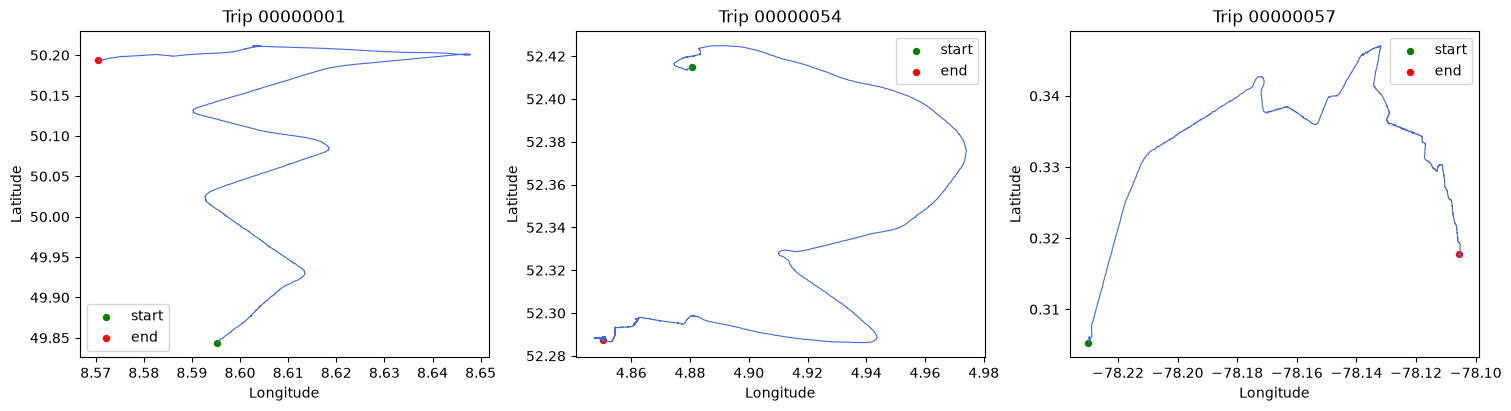

In [3]:
import matplotlib.pyplot as plt
from src.load import load_trip

example_ids = ['00000001', '00000054', '00000057']
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for ax, tid in zip(axes, example_ids):
    trk, _, _, _ = load_trip('train', tid)
    ax.plot(trk.lon, trk.lat, linewidth=0.8, color='royalblue')
    ax.scatter(trk.lon.iloc[0], trk.lat.iloc[0], s=18, color='green', label='start')
    ax.scatter(trk.lon.iloc[-1], trk.lat.iloc[-1], s=18, color='red', label='end')
    ax.set_title(f'Trip {tid}')
    ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude'); ax.legend()
plt.show()

## 4. Interactive GPS and reference-route map

Blue marks show observed GPS points; green lines show route arcs. The map is centered on trip 54, a useful case to inspect because many GPS points have no candidate within the current search configuration.

In [4]:
import folium

tid = '00000054'
trk, nodes, arcs, route = load_trip('train', tid)
center = [trk.lat.mean(), trk.lon.mean()]
m = folium.Map(location=center, zoom_start=12, tiles='OpenStreetMap')
folium.PolyLine(trk[['lat', 'lon']].to_numpy().tolist(), color='blue', weight=3, opacity=0.8, tooltip='GPS track').add_to(m)
route_ids = set(pd.Series(route).astype(int).tolist())
for arc_id in route_ids:
    if 0 <= arc_id < len(arcs):
        u, v = arcs.iloc[arc_id][['u', 'v']].astype(int)
        if 0 <= u < len(nodes) and 0 <= v < len(nodes):
            folium.PolyLine([[nodes.iloc[u].lat, nodes.iloc[u].lon], [nodes.iloc[v].lat, nodes.iloc[v].lon]],
                            color='green', weight=3, opacity=0.65, tooltip='Reference route').add_to(m)
folium.CircleMarker(center, radius=4, color='blue', fill=True, tooltip='Trip center').add_to(m)
m

## 5. Data-quality observations

The refreshed stats report 16,178 of 19,313 points in trip 54 with no candidate (83.8%); 17,211 points (89.1%) in that trip have no positive route label. Trip 21 has 7 of 15,783 points with no candidate (0.04%). The route-label miss rates are high for trips 6 (38.3%), 26 (42.9%), and 33 (67.9%). These are anomalies in the current outputs; this audit does not establish their cause.

Trip 57's raw file in this workspace has 1,645 complete rows and no null-valued rows, despite the earlier schedule mentioning NaNs. Its timestamps run from 1 to 1,670, leaving 25 integer timestamps unobserved. Treat the NaN claim as unconfirmed for this copy; the loader still drops rows with null fields defensively.